# EDA DGSIAP/ SNIIM

## Pregunta de investigación
Al cruzar los datos del SNIIM con la producción en el dgsiap tomamos la pregunta: “¿Cómo varían precios y producción entre años y regiones?”

## 0.0 Cargamos los módulosdatos

In [6]:
import pandas as pd
from rendimiento_bachoco.config import *
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.colors import Normalize

In [7]:
sniim = pd.read_csv(PROCESSED_DATA_DIR / 'sniim_maiz_blanco_mensual.csv')
dgsiap = pd.read_csv(PROCESSED_DATA_DIR / 'dgsiap_maiz.csv', index_col = 0)
display(sniim)
display(dgsiap)

,fecha,estado_mercado,mercado,origen,producto,precio_mxn_kg
0,2013-01-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.36
1,2013-02-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.00
2,2013-03-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.50
3,2013-04-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.24
4,2013-05-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.62
...,...,...,...,...,...,...
955,2025-08-01,Nuevo León,Guadalupe,Tamaulipas,Maíz blanco,10.67
956,2025-09-01,Nuevo León,Guadalupe,Tamaulipas,Maíz blanco,11.12
957,2025-10-01,Nuevo León,Guadalupe,Tamaulipas,Maíz blanco,11.30
958,2025-11-01,Nuevo León,Guadalupe,Tamaulipas,Maíz blanco,11.25


,Anio,Rendimiento,Precio,Valorproduccion,Volumenproduccion
Nomestado,,,,,
Ciudad de México,2013,1.530000,4588.737143,3.646553e+06,5250.60
Ciudad de México,2014,1.481429,4678.715714,3.817010e+06,5399.66
Ciudad de México,2015,1.441429,4793.194286,3.487688e+06,4836.99
Ciudad de México,2016,1.491429,4801.738571,3.471498e+06,5059.65
Ciudad de México,2017,1.378571,4898.654286,3.161782e+06,4533.44
...,...,...,...,...,...
Sonora,2021,6.154400,5415.408000,5.296686e+07,788885.77
Sonora,2022,7.853750,6832.362500,2.576911e+07,185958.83
Sonora,2023,7.267619,6616.784127,4.775809e+07,503014.40


## 1. Preparación
SNIIM viene a nivel mes × mercado × origen y en MXN/kg; DGSIAP a nivel estado × año y con `Precio` en MXN/ton.
Homologamos unidades (MXN/kg) y agregamos columnas de año y mes para poder cruzar.


In [9]:
sniim['fecha'] = pd.to_datetime(sniim['fecha'])
sniim['anio'] = sniim['fecha'].dt.year
sniim['mes'] = sniim['fecha'].dt.month
# 'producto' es constante (solo maíz blanco), no aporta información.
sniim = sniim.drop(columns='producto')

dgsiap = dgsiap.reset_index()
dgsiap['precio_productor_kg'] = dgsiap['Precio'] / 1000

display(sniim.head())
display(dgsiap.head())


,fecha,estado_mercado,mercado,origen,precio_mxn_kg,anio,mes
0,2013-01-01,Sonora,Hermosillo,Sinaloa,6.36,2013,1
1,2013-02-01,Sonora,Hermosillo,Sinaloa,6.00,2013,2
2,2013-03-01,Sonora,Hermosillo,Sinaloa,6.50,2013,3
3,2013-04-01,Sonora,Hermosillo,Sinaloa,6.24,2013,4
4,2013-05-01,Sonora,Hermosillo,Sinaloa,5.62,2013,5


,Nomestado,Anio,Rendimiento,Precio,Valorproduccion,Volumenproduccion,precio_productor_kg
0,Ciudad de México,2013,1.530000,4588.737143,3.646553e+06,5250.60,4.588737
1,Ciudad de México,2014,1.481429,4678.715714,3.817010e+06,5399.66,4.678716
2,Ciudad de México,2015,1.441429,4793.194286,3.487688e+06,4836.99,4.793194
3,Ciudad de México,2016,1.491429,4801.738571,3.471498e+06,5059.65,4.801739
4,Ciudad de México,2017,1.378571,4898.654286,3.161782e+06,4533.44,4.898654


## 2. Perfil SNIIM

In [10]:
print(f'Filas: {len(sniim)}, columnas: {sniim.shape[1]}')
print(f"Rango: {sniim['fecha'].min():%Y-%m} a {sniim['fecha'].max():%Y-%m}")
print(f"Duplicados (fecha, mercado, origen): {sniim.duplicated(['fecha', 'mercado', 'origen']).sum()}")
print(f"Nulos en precio: {sniim['precio_mxn_kg'].isna().sum()} ({sniim['precio_mxn_kg'].isna().mean():.1%})")

# Cobertura de cada serie mercado–origen: nos dice qué series son utilizables.
cobertura_sniim = (
    sniim.groupby(['estado_mercado', 'mercado', 'origen'])
    .agg(
        meses=('fecha', 'size'),
        desde=('fecha', 'min'),
        hasta=('fecha', 'max'),
        nulos=('precio_mxn_kg', lambda x: x.isna().sum()),
        mediana=('precio_mxn_kg', 'median'),
    )
)
cobertura_sniim['pct_nulos'] = cobertura_sniim['nulos'] / cobertura_sniim['meses']
cobertura_sniim['alerta'] = np.where(cobertura_sniim['pct_nulos'] > 0.20, 'escasa (>20% nulos)', '')
display(cobertura_sniim.sort_values(['estado_mercado', 'meses'], ascending=[True, False]))

# Serie principal por mercado: cada mes tomamos el origen con más meses observados en ese mercado.
# Solo cambiamos de origen cuando el principal no se reporta en ese periodo (no para rellenar nulos sueltos),
# así Hermosillo queda continua (Sinaloa hasta 2018, Sonora desde 2019) sin mezclar orígenes en el resto.
prioridad_origen = (
    sniim.groupby(['estado_mercado', 'origen'])['precio_mxn_kg'].count()
    .groupby(level='estado_mercado').rank(ascending=False, method='first')
    .rename('prioridad')
    .reset_index()
)
sniim_principal = (
    sniim.merge(prioridad_origen, on=['estado_mercado', 'origen'])
    .sort_values('prioridad')
    .drop_duplicates(['estado_mercado', 'fecha'])
    .dropna(subset=['precio_mxn_kg'])
    .sort_values(['estado_mercado', 'fecha'])
    .reset_index(drop=True)
)
display(
    sniim_principal.groupby(['estado_mercado', 'origen'])['fecha']
    .agg(['min', 'max', 'size'])
    .rename(columns={'size': 'meses_usados'})
)


Filas: 960, columnas: 7
Rango: 2013-01 a 2025-12
Duplicados (fecha, mercado, origen): 0
Nulos en precio: 169 (17.6%)


meses      desde      hasta  nulos  \
estado_mercado   mercado     origen                                            
Ciudad de México Iztapalapa  Sinaloa        156 2013-01-01 2025-12-01     15   
                             México          24 2014-01-01 2015-12-01      9   
Jalisco          Guadalajara Jalisco        156 2013-01-01 2025-12-01     13   
                             Importación     36 2013-01-01 2020-12-01     21   
Nuevo León       Guadalupe   Tamaulipas     156 2013-01-01 2025-12-01     15   
                             Sinaloa         36 2016-01-01 2018-12-01     16   
                             Coahuila        12 2019-01-01 2019-12-01      9   
                             Tabasco         12 2019-01-01 2019-12-01     10   
Sinaloa          Culiacán    Sinaloa        156 2013-01-01 2025-12-01     21   
                             Jalisco         48 2013-01-01 2016-12-01     23   
Sonora           Hermosillo  Sonora          84 2019-01-01 2025-12-01      6   
                             Sinaloa         72 2013-01-01 2018-12-01      4   
                             Jalisco         12 2019-01-01 2019-12-01      7   

                                          mediana  pct_nulos  \
estado_mercado   mercado     origen                            
Ciudad de México Iztapalapa  Sinaloa        6.580   0.096154   
                             México         4.800   0.375000   
Jalisco          Guadalajara Jalisco        5.580   0.083333   
                             Importación    5.000   0.583333   
Nuevo León       Guadalupe   Tamaulipas     6.700   0.096154   
                             Sinaloa        5.945   0.444444   
                             Coahuila       6.000   0.750000   
                             Tabasco        6.100   0.833333   
Sinaloa          Culiacán    Sinaloa        6.000   0.134615   
                             Jalisco        4.400   0.479167   
Sonora           Hermosillo  Sonora         9.560   0.071429   
                             Sinaloa        5.610   0.055556   
                             Jalisco        7.500   0.583333   

                                                       alerta  
estado_mercado   mercado     origen                            
Ciudad de México Iztapalapa  Sinaloa                           
                             México       escasa (>20% nulos)  
Jalisco          Guadalajara Jalisco                           
                             Importación  escasa (>20% nulos)  
Nuevo León       Guadalupe   Tamaulipas                        
                             Sinaloa      escasa (>20% nulos)  
                             Coahuila     escasa (>20% nulos)  
                             Tabasco      escasa (>20% nulos)  
Sinaloa          Culiacán    Sinaloa                           
                             Jalisco      escasa (>20% nulos)  
Sonora           Hermosillo  Sonora                            
                             Sinaloa                           
                             Jalisco      escasa (>20% nulos)

min        max  meses_usados
estado_mercado   origen                                        
Ciudad de México Sinaloa    2013-01-01 2025-12-01           141
Jalisco          Jalisco    2013-01-01 2025-12-01           143
Nuevo León       Tamaulipas 2013-01-01 2025-12-01           141
Sinaloa          Sinaloa    2013-01-01 2025-12-01           135
Sonora           Sinaloa    2013-01-01 2018-08-01            68
                 Sonora     2019-02-01 2025-12-01            78

## 3. Perfil DGSIAP

In [11]:
print(f'Filas: {len(dgsiap)} (estados: {dgsiap["Nomestado"].nunique()}, años: {dgsiap["Anio"].nunique()})')
print(f"Duplicados (Nomestado, Anio): {dgsiap.duplicated(['Nomestado', 'Anio']).sum()}")
print(f'Nulos totales: {dgsiap.isna().sum().sum()}')

metricas_dgsiap = ['Rendimiento', 'precio_productor_kg', 'Valorproduccion', 'Volumenproduccion']
perfil_dgsiap = dgsiap[metricas_dgsiap].describe(percentiles=[.05, .25, .5, .75, .95]).T
perfil_dgsiap['sesgo'] = dgsiap[metricas_dgsiap].skew()
display(perfil_dgsiap)

# La escala de volumen entre estados difiere en órdenes de magnitud, por eso usaremos escala log.
display(dgsiap.groupby('Nomestado')['Volumenproduccion'].agg(['min', 'median', 'max']))


Filas: 65 (estados: 5, años: 13)
Duplicados (Nomestado, Anio): 0
Nulos totales: 0


,count,mean,std,min,5%,25%,50%,75%,95%,max,sesgo
Rendimiento,65.0,4.688135e+00,2.626165e+00,1.282857e+00,1.378857e+00,1.935510e+00,5.620000e+00,6.856531e+00,8.468476e+00,8.960938e+00,-0.011472
precio_productor_kg,65.0,4.556482e+00,1.223526e+00,2.833529e+00,3.078555e+00,3.467421e+00,4.493680e+00,5.415408e+00,6.749262e+00,7.405860e+00,0.547848
Valorproduccion,65.0,7.717209e+07,1.078124e+08,2.967002e+06,3.194876e+06,4.697398e+06,1.773134e+07,1.170730e+08,2.555721e+08,4.272799e+08,1.755384
Volumenproduccion,65.0,1.854410e+06,2.266427e+06,3.990420e+03,4.403168e+03,3.642406e+04,1.859588e+05,3.686274e+06,6.272114e+06,6.656331e+06,0.782747


,min,median,max
Nomestado,,,
Ciudad de México,3990.42,4834.45,5399.66
Jalisco,3303498.08,3818364.89,4024863.86
Nuevo León,23911.92,55215.55,99732.93
Sinaloa,2275224.24,5535561.11,6656330.77
Sonora,113533.73,185958.83,788885.77


## 4. Precio mayorista en el tiempo (SNIIM)

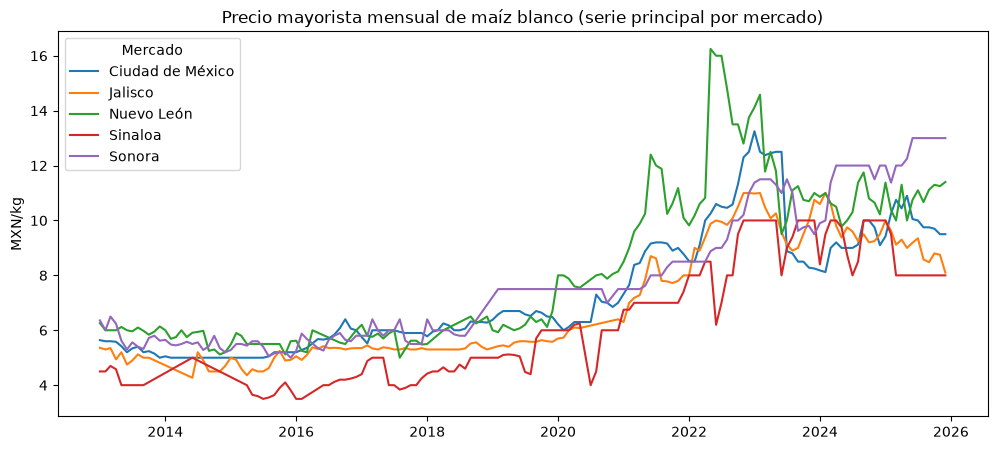

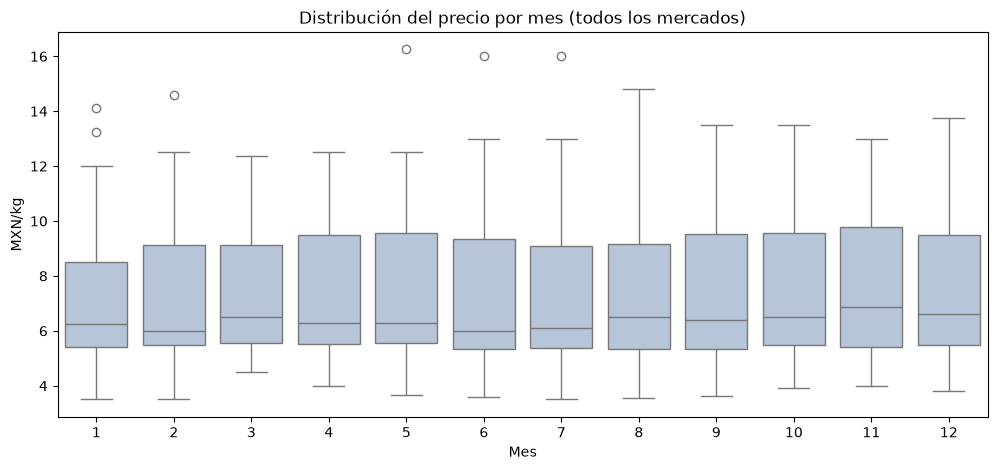

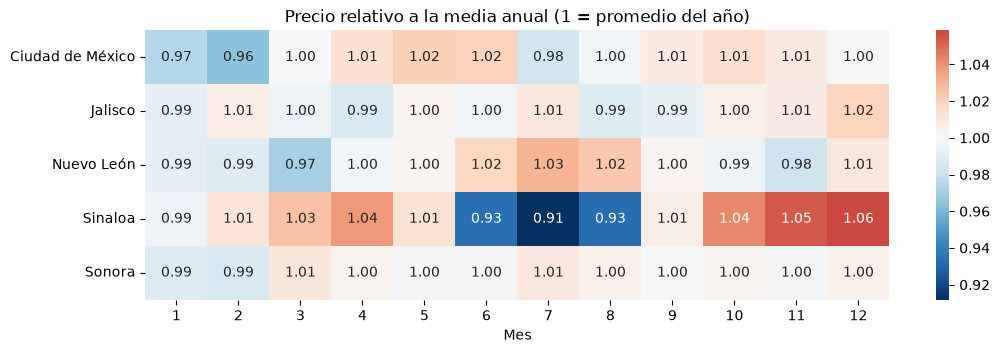

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=sniim_principal, x='fecha', y='precio_mxn_kg', hue='estado_mercado', ax=ax)
ax.set(title='Precio mayorista mensual de maíz blanco (serie principal por mercado)',
       xlabel='', ylabel='MXN/kg')
ax.legend(title='Mercado')
plt.show()

# Estacionalidad: ¿hay meses sistemáticamente más caros?
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=sniim_principal, x='mes', y='precio_mxn_kg', ax=ax, color='lightsteelblue')
ax.set(title='Distribución del precio por mes (todos los mercados)', xlabel='Mes', ylabel='MXN/kg')
plt.show()

# Para quitar el efecto de la tendencia, comparamos cada mes contra la media de su año y mercado.
sniim_principal['precio_rel_anio'] = (
    sniim_principal['precio_mxn_kg']
    / sniim_principal.groupby(['estado_mercado', 'anio'])['precio_mxn_kg'].transform('mean')
)
estacionalidad = sniim_principal.pivot_table(index='estado_mercado', columns='mes',
                                             values='precio_rel_anio', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(estacionalidad, cmap='RdBu_r', center=1, annot=True, fmt='.2f', ax=ax)
ax.set(title='Precio relativo a la media anual (1 = promedio del año)', xlabel='Mes', ylabel='')
plt.show()



## 5. Precios entre regiones (SNIIM anual)

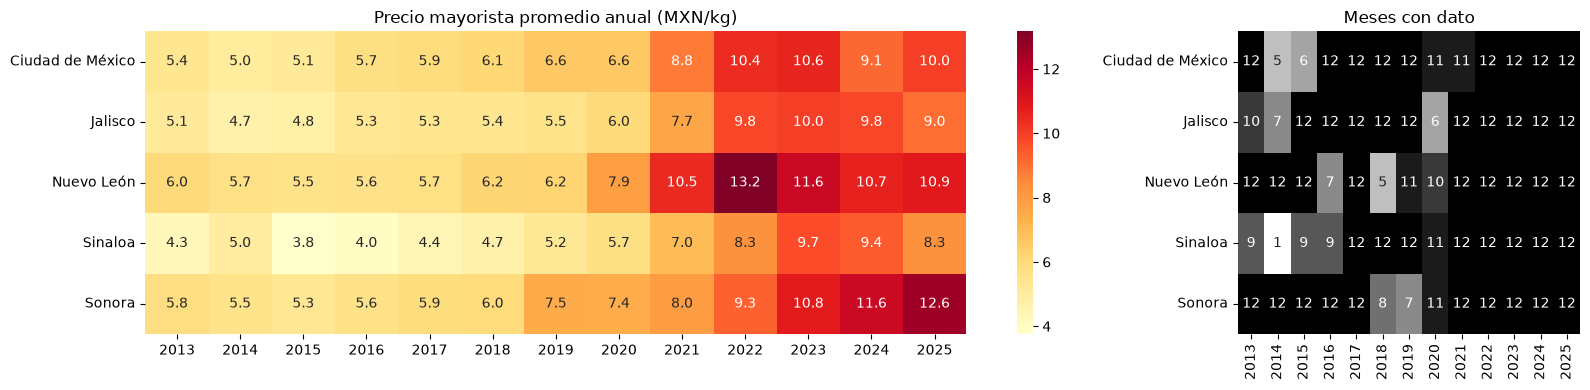

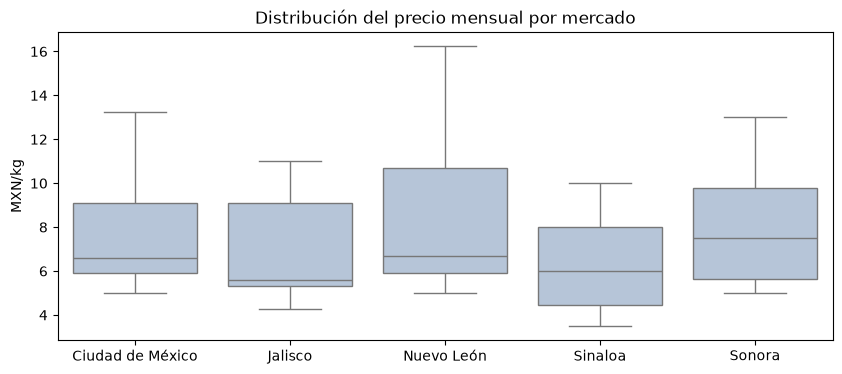

anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
estado_mercado,,,,,,,,,,,,,
Ciudad de México,,-6.6%,2.6%,11.5%,3.0%,3.7%,7.8%,-0.2%,33.6%,18.1%,1.7%,-13.7%,9.6%
Jalisco,,-8.6%,2.4%,10.7%,1.3%,0.2%,3.3%,8.5%,27.8%,27.7%,1.8%,-1.8%,-7.8%
Nuevo León,,-6.2%,-2.2%,1.0%,1.8%,8.1%,1.1%,27.3%,32.3%,25.8%,-12.0%,-8.1%,2.2%
Sinaloa,,17.6%,-25.0%,6.8%,8.7%,7.9%,11.6%,9.1%,22.2%,18.8%,16.8%,-3.0%,-11.9%
Sonora,,-5.3%,-2.8%,5.3%,4.4%,2.1%,25.4%,-0.9%,7.0%,16.7%,16.1%,7.3%,8.5%


Desv. estándar promedio entre años (dentro de cada mercado): 2.34 MXN/kg
Desv. estándar promedio entre mercados (dentro de cada año): 0.94 MXN/kg


In [13]:
sniim_anual = (
    sniim_principal.groupby(['estado_mercado', 'anio'])
    .agg(precio_mayorista_kg=('precio_mxn_kg', 'mean'),
         meses_observados=('precio_mxn_kg', 'count'))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(sniim_anual.pivot(index='estado_mercado', columns='anio', values='precio_mayorista_kg'),
            cmap='YlOrRd', annot=True, fmt='.1f', ax=axes[0])
axes[0].set(title='Precio mayorista promedio anual (MXN/kg)', xlabel='', ylabel='')
sns.heatmap(sniim_anual.pivot(index='estado_mercado', columns='anio', values='meses_observados'),
            cmap='Greys', annot=True, fmt='.0f', cbar=False, ax=axes[1])
axes[1].set(title='Meses con dato', xlabel='', ylabel='')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=sniim_principal, x='estado_mercado', y='precio_mxn_kg', ax=ax, color='lightsteelblue')
ax.set(title='Distribución del precio mensual por mercado', xlabel='', ylabel='MXN/kg')
plt.show()

# Variación anual (%) para ver si los mercados se mueven juntos.
sniim_anual['var_anual'] = sniim_anual.groupby('estado_mercado')['precio_mayorista_kg'].pct_change()
display(
    sniim_anual.pivot(index='estado_mercado', columns='anio', values='var_anual')
    .style.format('{:.1%}', na_rep='').background_gradient(cmap='RdBu_r', vmin=-0.4, vmax=0.4)
)

# ¿Pesa más el año o la región? Comparamos la dispersión entre años vs entre mercados.
pivote_precio = sniim_anual.pivot(index='estado_mercado', columns='anio', values='precio_mayorista_kg')
print(f'Desv. estándar promedio entre años (dentro de cada mercado): {pivote_precio.std(axis=1).mean():.2f} MXN/kg')
print(f'Desv. estándar promedio entre mercados (dentro de cada año): {pivote_precio.std(axis=0).mean():.2f} MXN/kg')


## 6. Producción entre años y regiones (DGSIAP)

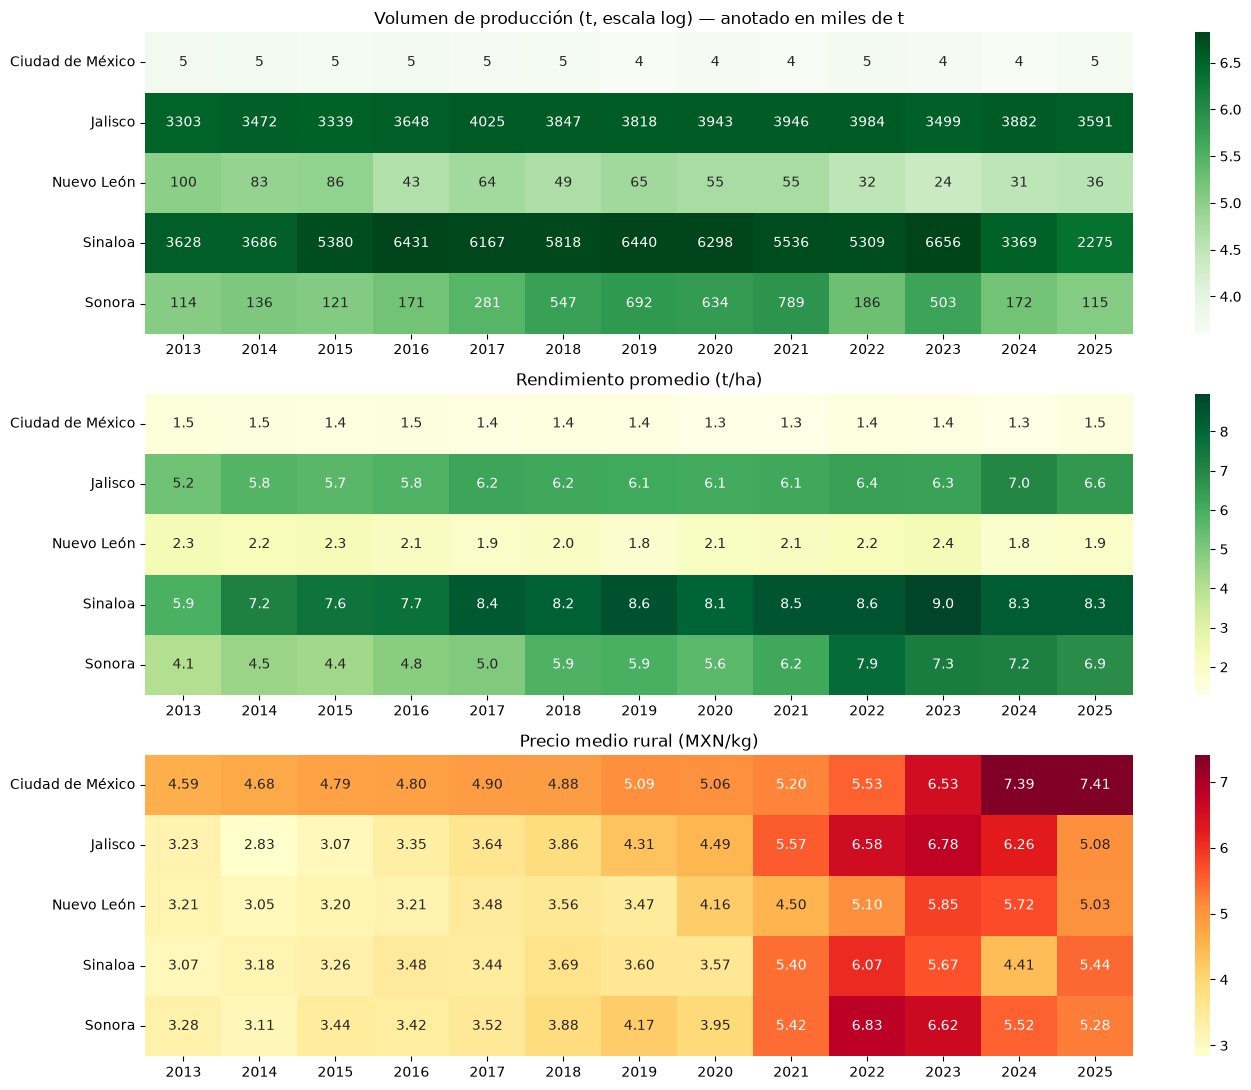

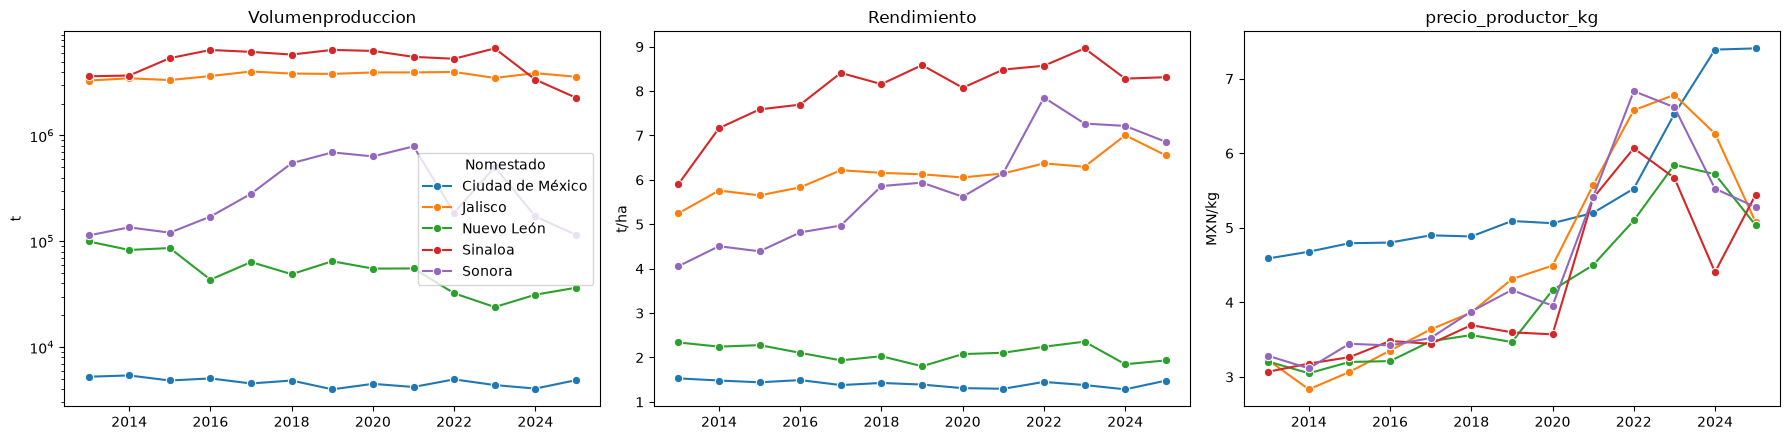

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
heatmaps_dgsiap = [
    ('Volumenproduccion', 'Volumen de producción (t, escala log)', 'Greens', True, '.0f'),
    ('Rendimiento', 'Rendimiento promedio (t/ha)', 'YlGn', False, '.1f'),
    ('precio_productor_kg', 'Precio medio rural (MXN/kg)', 'YlOrRd', False, '.2f'),
]
for ax, (columna, titulo, cmap, log, fmt) in zip(axes, heatmaps_dgsiap):
    tabla = dgsiap.pivot(index='Nomestado', columns='Anio', values=columna)
    sns.heatmap(np.log10(tabla) if log else tabla, cmap=cmap, ax=ax,
                annot=tabla if not log else tabla / 1000, fmt=fmt if not log else '.0f')
    ax.set(title=titulo if not log else titulo + ' — anotado en miles de t', xlabel='', ylabel='')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, columna, etiqueta in zip(axes,
                                 ['Volumenproduccion', 'Rendimiento', 'precio_productor_kg'],
                                 ['t', 't/ha', 'MXN/kg']):
    sns.lineplot(data=dgsiap, x='Anio', y=columna, hue='Nomestado', marker='o', ax=ax, legend=ax is axes[0])
    ax.set(title=columna, xlabel='', ylabel=etiqueta)
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()


## 7. Cruce SNIIM × DGSIAP
Unimos por **estado del mercado** y año. Ojo: el estado del mercado no siempre es el estado de origen del grano
(p. ej. Iztapalapa recibe maíz de Sinaloa), así que el margen es entre el precio al productor *del estado* y el precio mayorista *en el estado*.


_merge
both          65
left_only      0
right_only     0
Name: count, dtype: int64


,estado_mercado,anio,precio_mayorista_kg,precio_productor_kg,margen_kg,margen_pct,Volumenproduccion,Rendimiento
0,Ciudad de México,2013,5.364167,4.588737,0.775430,0.168985,5250.60,1.530000
1,Ciudad de México,2014,5.010000,4.678716,0.331284,0.070807,5399.66,1.481429
2,Ciudad de México,2015,5.141667,4.793194,0.348472,0.072701,4836.99,1.441429
3,Ciudad de México,2016,5.731667,4.801739,0.929928,0.193665,5059.65,1.491429
4,Ciudad de México,2017,5.900833,4.898654,1.002179,0.204583,4533.44,1.378571
5,Ciudad de México,2018,6.118333,4.884059,1.234275,0.252715,4834.45,1.427143
6,Ciudad de México,2019,6.598333,5.091001,1.507332,0.296078,3990.42,1.390000
7,Ciudad de México,2020,6.584545,5.061439,1.523107,0.300924,4495.92,1.310000
8,Ciudad de México,2021,8.796364,5.199827,3.596536,0.691665,4200.13,1.295714
9,Ciudad de México,2022,10.385833,5.525243,4.860590,0.879706,4954.90,1.450000


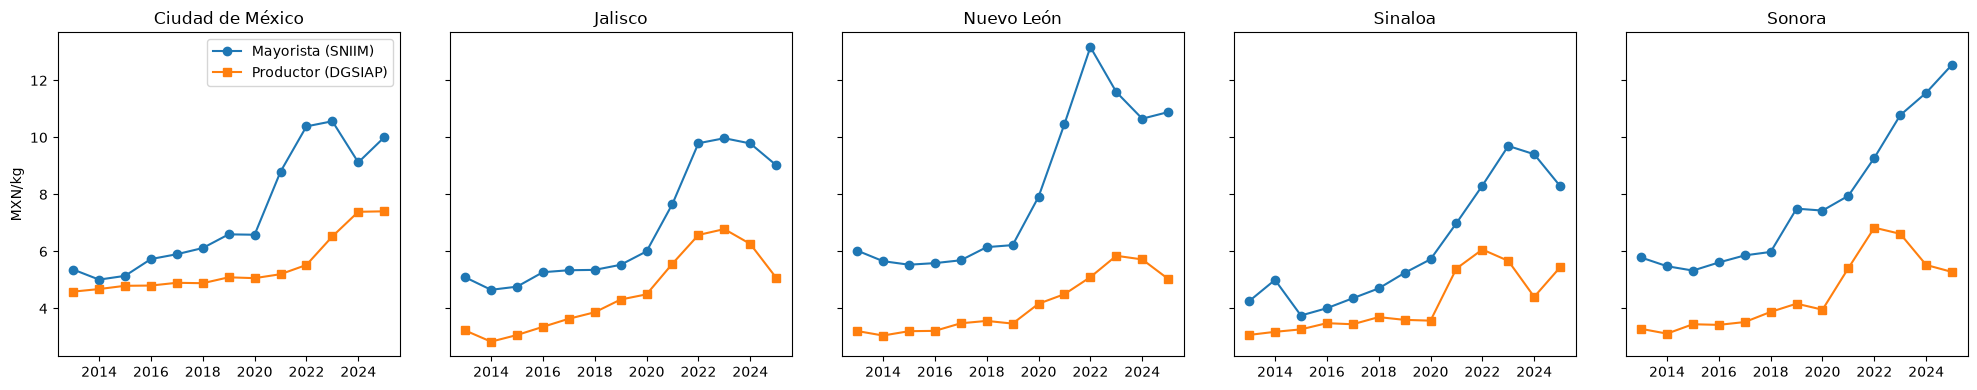

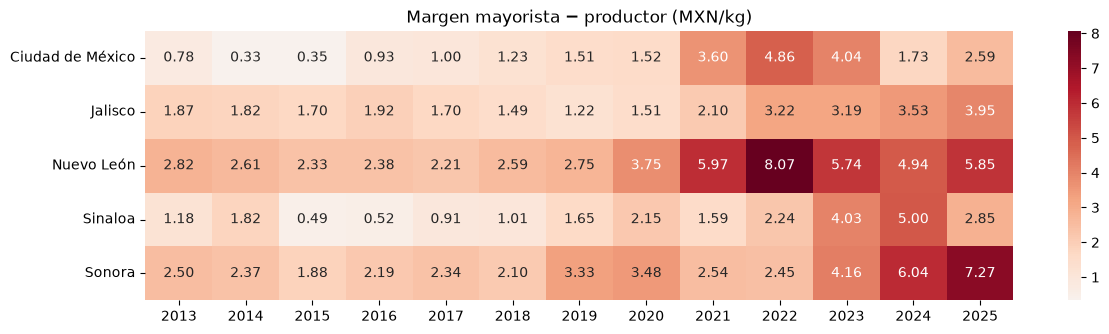

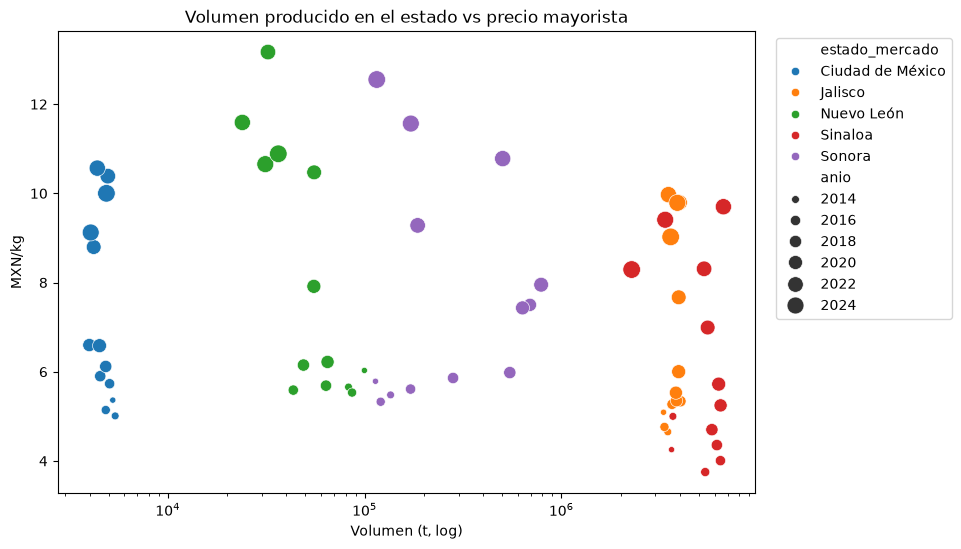

In [16]:
cruce = sniim_anual.merge(
    dgsiap.rename(columns={'Nomestado': 'estado_mercado', 'Anio': 'anio'}),
    on=['estado_mercado', 'anio'], how='outer', indicator=True,
)
print(cruce['_merge'].value_counts())
cruce = cruce.query('_merge == "both"').drop(columns='_merge')
cruce['margen_kg'] = cruce['precio_mayorista_kg'] - cruce['precio_productor_kg']
cruce['margen_pct'] = cruce['margen_kg'] / cruce['precio_productor_kg']
display(cruce[['estado_mercado', 'anio', 'precio_mayorista_kg', 'precio_productor_kg',
               'margen_kg', 'margen_pct', 'Volumenproduccion', 'Rendimiento']].head(15))

estados = sorted(cruce['estado_mercado'].unique())
fig, axes = plt.subplots(1, len(estados), figsize=(20, 4), sharey=True)
for ax, estado in zip(axes, estados):
    datos = cruce[cruce['estado_mercado'] == estado]
    ax.plot(datos['anio'], datos['precio_mayorista_kg'], marker='o', label='Mayorista (SNIIM)')
    ax.plot(datos['anio'], datos['precio_productor_kg'], marker='s', label='Productor (DGSIAP)')
    ax.set(title=estado, xlabel='')
axes[0].set_ylabel('MXN/kg')
axes[0].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(cruce.pivot(index='estado_mercado', columns='anio', values='margen_kg'),
            cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=ax)
ax.set(title='Margen mayorista − productor (MXN/kg)', xlabel='', ylabel='')
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=cruce, x='Volumenproduccion', y='precio_mayorista_kg', hue='estado_mercado',
                size='anio', sizes=(20, 160), ax=ax)
ax.set_xscale('log')
ax.set(title='Volumen producido en el estado vs precio mayorista', xlabel='Volumen (t, log)', ylabel='MXN/kg')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


### Cruce alternativo por estado de origen
Si unimos por `origen` (de dónde viene el grano) en lugar del estado del mercado, solo algunos orígenes existen en DGSIAP.


In [17]:
origenes = sniim_principal[['estado_mercado', 'origen']].drop_duplicates()
origenes['origen_en_dgsiap'] = origenes['origen'].isin(dgsiap['Nomestado'])
origenes['mismo_estado'] = origenes['origen'] == origenes['estado_mercado']
display(origenes)


,estado_mercado,origen,origen_en_dgsiap,mismo_estado
0,Ciudad de México,Sinaloa,True,False
141,Jalisco,Jalisco,True,True
284,Nuevo León,Tamaulipas,False,False
425,Sinaloa,Sinaloa,True,True
560,Sonora,Sinaloa,True,False
628,Sonora,Sonora,True,True


## 8. Correlaciones
Spearman, porque las métricas son sesgadas y n es pequeño (13 años por estado). Correlación ≠ causalidad.


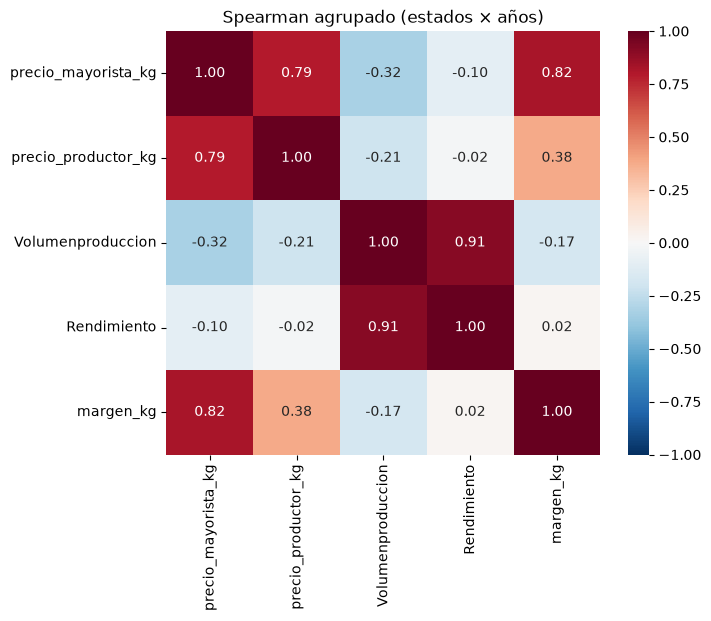

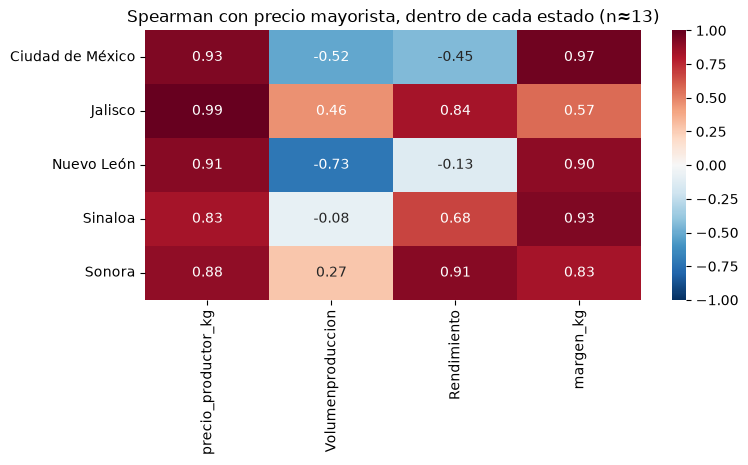

In [18]:
variables_corr = ['precio_mayorista_kg', 'precio_productor_kg', 'Volumenproduccion', 'Rendimiento', 'margen_kg']

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cruce[variables_corr].corr(method='spearman'), cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, annot=True, fmt='.2f', ax=ax)
ax.set(title='Spearman agrupado (estados × años)')
plt.show()

# Dentro de cada estado (solo variación temporal), para no confundir diferencias de escala entre regiones.
corr_por_estado = pd.DataFrame({
    estado: grupo[variables_corr].corr(method='spearman')['precio_mayorista_kg'].drop('precio_mayorista_kg')
    for estado, grupo in cruce.groupby('estado_mercado')
}).T
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(corr_por_estado, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=ax)
ax.set(title='Spearman con precio mayorista, dentro de cada estado (n≈13)', ylabel='')
plt.show()


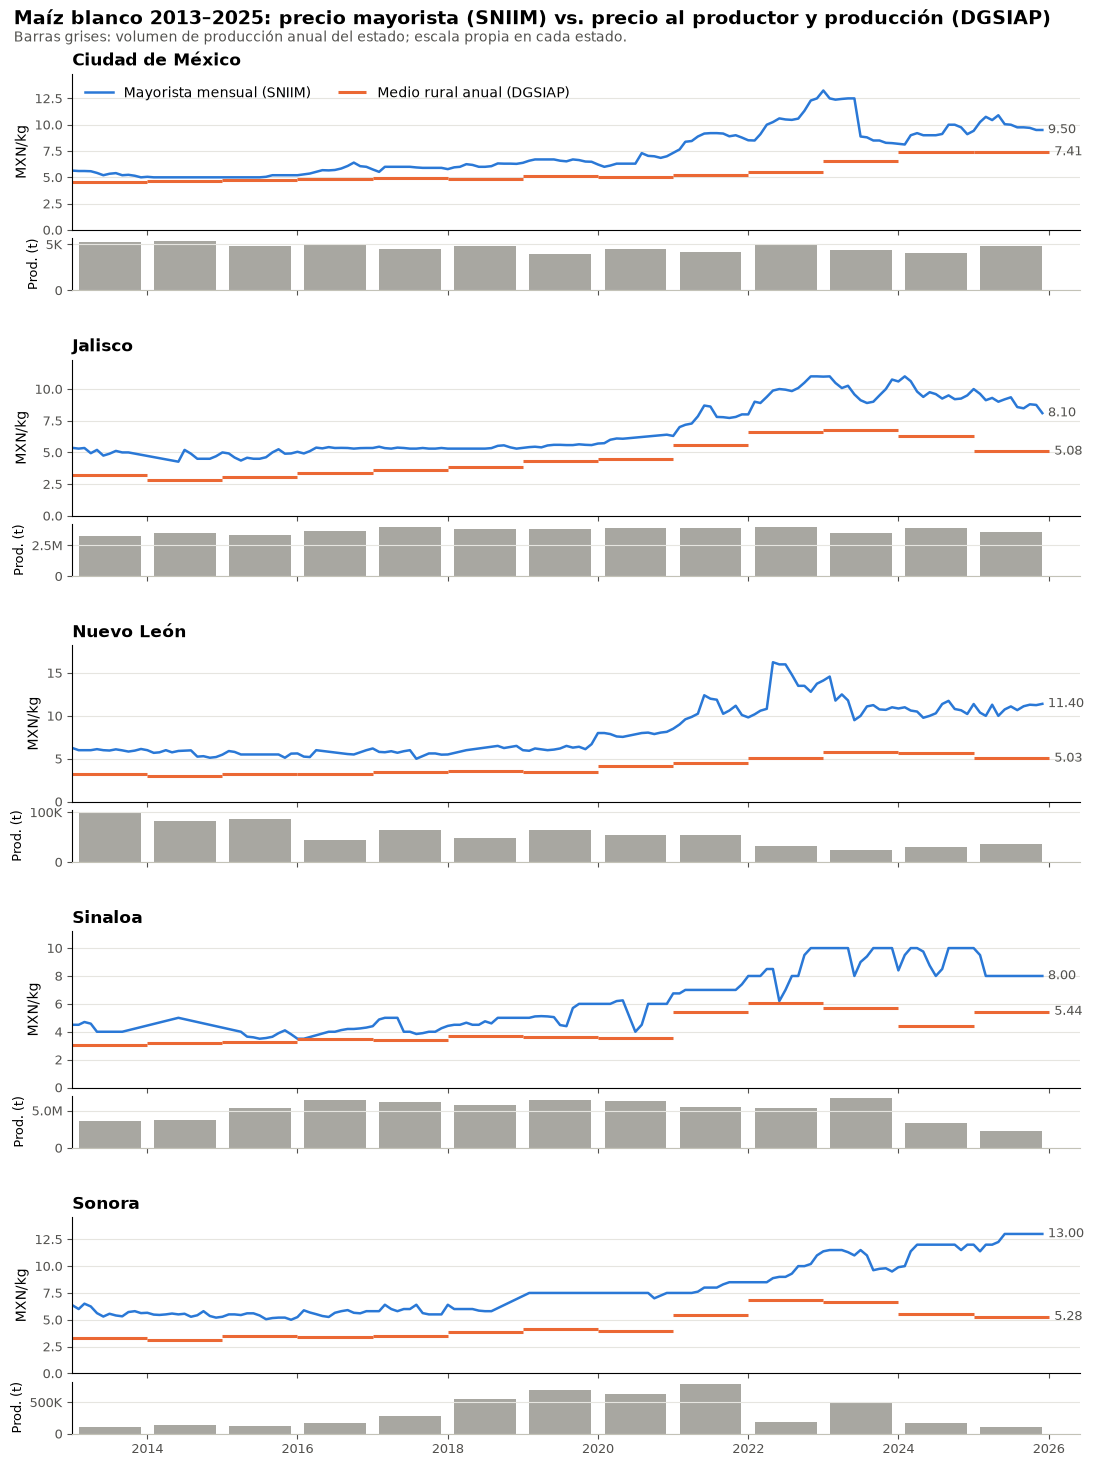

In [20]:
from matplotlib.ticker import FuncFormatter

COLOR_SNIIM, COLOR_DGSIAP, COLOR_VOL = '#2a78d6', '#eb6834', '#a8a7a1'
estados = sorted(dgsiap['Nomestado'].unique())

# DGSIAP es anual: lo dibujamos como escalón de enero a diciembre para alinearlo con los meses de SNIIM.
linea_dgsiap = dgsiap.copy()
linea_dgsiap['inicio'] = pd.to_datetime(linea_dgsiap['Anio'].astype(str) + '-01-01')
linea_dgsiap['fin'] = pd.to_datetime((linea_dgsiap['Anio'] + 1).astype(str) + '-01-01')

fig = plt.figure(figsize=(13, 17))
gs_estados = fig.add_gridspec(len(estados), 1, hspace=0.32, top=0.91)
ax_ref = None
for i, estado in enumerate(estados):
    gs = gs_estados[i].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax_p = fig.add_subplot(gs[0], sharex=ax_ref)
    ax_ref = ax_ref or ax_p
    ax_v = fig.add_subplot(gs[1], sharex=ax_ref)

    s = sniim_principal[sniim_principal['estado_mercado'] == estado]
    d = linea_dgsiap[linea_dgsiap['Nomestado'] == estado].sort_values('Anio')

    ax_p.plot(s['fecha'], s['precio_mxn_kg'], color=COLOR_SNIIM, lw=1.8, label='Mayorista mensual (SNIIM)')
    ax_p.hlines(d['precio_productor_kg'], d['inicio'], d['fin'], color=COLOR_DGSIAP, lw=2.2,
                label='Medio rural anual (DGSIAP)')
    # Etiqueta directa en el último punto de cada serie.
    ax_p.annotate(f"{s['precio_mxn_kg'].iloc[-1]:.2f}", (s['fecha'].iloc[-1], s['precio_mxn_kg'].iloc[-1]),
                  xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color='#52514e')
    ax_p.annotate(f"{d['precio_productor_kg'].iloc[-1]:.2f}", (d['fin'].iloc[-1], d['precio_productor_kg'].iloc[-1]),
                  xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color='#52514e')
    ax_p.set_ylim(0, max(s['precio_mxn_kg'].max(), d['precio_productor_kg'].max()) * 1.12)
    ax_p.set_ylabel('MXN/kg', fontsize=10)
    ax_p.set_title(estado, loc='left', fontsize=12, fontweight='bold')

    ax_v.bar(d['inicio'] + pd.Timedelta(days=182), d['Volumenproduccion'], width=300, color=COLOR_VOL)
    ax_v.yaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f'{v / 1e6:.1f}M' if v >= 1e6 else f'{v / 1e3:.0f}K' if v else '0'))
    ax_v.set_ylabel('Prod. (t)', fontsize=9)
    ax_v.set_ylim(0, None)
    ax_v.locator_params(axis='y', nbins=2)

    for ax in (ax_p, ax_v):
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', color='#e6e5e0', lw=0.8)
        ax.grid(axis='x', visible=False)
        ax.tick_params(labelsize=9, colors='#52514e')
        if ax is not ax_v or i < len(estados) - 1:
            ax.tick_params(labelbottom=False)
    ax_v.spines['bottom'].set_color('#c3c2b7')

ax_ref.legend(loc='upper left', frameon=False, fontsize=10, ncol=2)
ax_ref.set_xlim(pd.Timestamp('2013-01-01'), pd.Timestamp('2026-06-01'))
fig.suptitle('Maíz blanco 2013–2025: precio mayorista (SNIIM) vs. precio al productor y producción (DGSIAP)',
             fontsize=14, fontweight='bold', x=0.08, ha='left', y=0.948)
fig.text(0.08, 0.929, 'Barras grises: volumen de producción anual del estado; escala propia en cada estado.',
         fontsize=10, color='#52514e')
plt.savefig(FIGURES_DIR / 'timeline_sniim_dgsiap.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Conclusiones

> Precios en MXN/kg nominales. **Margen** = precio mayorista (SNIIM) − precio al productor (DGSIAP).

1. **El precio casi se duplicó (+77% a +117%), con el salto en 2021–22.** Antes de 2021 el precio se mantuvo entre 5 y 6 MXN/kg. En 2021 y 2022 subió 20–35% por año, y después se estabilizó, salvo en Sonora, que siguió subiendo. Parte del aumento es inflación (~70–80% en el periodo, estimación externa al notebook).
2. **El aumento llegó menos al productor.** El precio al productor subió solo 57–77% y bajó después de 2023. El margen promedio pasó de **1.81 a 4.06 MXN/kg** (de ~50% a ~73% sobre el precio al productor). En Sonora pasó de 2.50 a 7.27.
3. **Pesa más el año que la región.** En promedio, el precio de un mercado varía 2.34 MXN/kg entre años y solo 0.94 entre mercados en un mismo año. Los cinco mercados se mueven juntos, lo que apunta a factores nacionales o externos.
4. **Casi no hay estacionalidad.** Ningún mes se desvía de forma consistente más de ±2% de la media anual. La excepción es Culiacán, con alrededor de ±6% según la época de cosecha.
5. **La cosecha local no fija el precio local.** La correlación entre volumen y precio es débil (−0.32 agrupada) y cambia de signo según el estado (de −0.73 en Nuevo León a +0.91 en Sonora).
6. **Los mercados que se abastecen de lejos tienen mayor margen.** Nuevo León (4.00) y Sonora (3.28) tienen los márgenes más altos, contra alrededor de 2 en Sinaloa, Jalisco y CDMX. Es una hipótesis por confirmar.

**Limitaciones:** solo 13 años por estado; el margen compara el estado del mercado y no el de origen del grano; algunos años tienen pocos meses con dato (Sinaloa 2014: 1 mes, CDMX 2014: 5); precios sin deflactar.

**Siguientes pasos:** deflactar con el INPC, agregar el precio internacional del maíz (CBOT) y el tipo de cambio, y recalcular el margen por estado de origen.
